# Dong et al. 2020 — Prostate Cancer (10x)
## 02 — EMT-TF expression (unconditional final step)

Gate 1 was **NO-GO** (sample-segregated manifold), so no trajectory is fit and the gate chain stops. The EMT-TF expression overlay is produced regardless (renumbered to 02 per §6). It reads `processed.h5ad` and overlays the two most broadly-detected EMT transcription factors on the malignant manifold — no pseudotime (there is no trajectory).

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [3]:
# read the processed malignant manifold (§6: expression reads processed.h5ad)
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('cells:', adata.shape[0], '| samples:', adata.obs['sample'].nunique())
adata

cells: 9698 | samples: 4


AnnData object with n_obs × n_vars = 9698 × 15672
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'celltype', 'Gast', 'pSom', 'Crest', 'cycling'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'cell_cycle_phase_colors', 'log1p', 'neighbors', 'pca', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

### EMT-TF candidate panel
Widened beyond Snail/Zeb/Twist to the FOXC and PRRX mesenchymal families (Kürten evaluation lesson: the canonical panel alone can miss the informative factor). **VIM is excluded** — vimentin is a mesenchymal marker, not a transcription factor (Chen 2020 lesson). For each candidate: detection fraction and mean-in-expressers; no pseudotime (Gate 1 NO-GO).

In [4]:
panel = ['SNAI1', 'SNAI2', 'ZEB1', 'ZEB2', 'TWIST1', 'TWIST2', 'FOXC1', 'FOXC2', 'PRRX1', 'PRRX2']
present = [g for g in panel if g in adata.var_names]
X = adata[:, present].X; X = X.toarray() if hasattr(X, 'toarray') else np.asarray(X)
rows = []
for j, g in enumerate(present):
    x = X[:, j]
    rows.append((g, round((x > 0).mean(), 3), round(x[x > 0].mean() if (x > 0).any() else 0, 3), round(float(x.max()), 2)))
df = pd.DataFrame(rows, columns=['TF', 'frac_expr', 'mean_in_expr', 'max']).sort_values('frac_expr', ascending=False)
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03].copy()
sel = ok.sort_values('frac_expr', ascending=False).head(2)['TF'].tolist()
print('\ndetectable EMT-TFs (frac>0.03):', ok.TF.tolist())
print('shown (two broadest):', sel)

    TF  frac_expr  mean_in_expr  max
TWIST1      0.268         1.105 2.74
 SNAI1      0.060         0.532 1.59
 PRRX2      0.035         0.473 1.38
 FOXC1      0.035         0.474 1.43
TWIST2      0.035         0.455 1.71
  ZEB2      0.024         0.474 1.53
  ZEB1      0.023         0.444 1.09
 SNAI2      0.020         0.473 2.05
 PRRX1      0.015         0.492 1.43

detectable EMT-TFs (frac>0.03): ['TWIST1', 'SNAI1', 'PRRX2', 'FOXC1', 'TWIST2']
shown (two broadest): ['TWIST1', 'SNAI1']


### Deliverable — `expression.pdf`
Reference style: categorical overlay of thresholded expressers (top decile among expressing cells per factor) on a grey manifold — not a continuous colormap (Sun 2021 lesson).

overlay thresholds (top decile among expressers): {'TWIST1': 1.88, 'SNAI1': 0.87} | cells shown: {'TWIST1': 260, 'SNAI1': 59}
TWIST1: 26.8% expressing; 260 shown (top decile)
SNAI1: 6.0% expressing; 59 shown (top decile)
saved expression.pdf


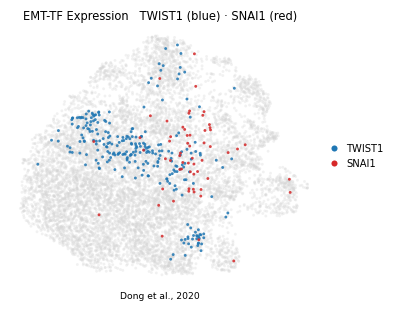

In [5]:
xy = adata.obsm['X_umap']
xlo, xhi = np.percentile(xy[:, 0], [0.3, 99.7]); ylo, yhi = np.percentile(xy[:, 1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.05
def _vec(g):
    x = adata[:, g].X
    return x.toarray().ravel() if hasattr(x, 'toarray') else np.asarray(x).ravel()
thr = {}
for g in sel:
    v = _vec(g); pos = v[v > 0]; thr[g] = float(np.quantile(pos, 0.90)) if pos.size else 0.0
seln = {g: _vec(g) > thr[g] for g in sel}
print('overlay thresholds (top decile among expressers):', {g: round(thr[g], 2) for g in thr},
      '| cells shown:', {g: int(seln[g].sum()) for g in seln})
order = sorted(sel, key=lambda g: -int(seln[g].sum()))
colors = {sel[0]: 'tab:blue', sel[1]: 'tab:red'}
fig, ax = plt.subplots(figsize=(3.5, 3.0))
sc.pl.umap(adata, size=14, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[seln[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=14, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.legend(handles=[Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[g],markersize=5,label=g) for g in sel],
          loc='center left', bbox_to_anchor=(1.02,.5), frameon=False, fontsize=6.5, handletextpad=.2)
ax.set_title(f'EMT-TF Expression   {sel[0]} (blue) \u00b7 {sel[1]} (red)', size=7.5)
ax.text(.5, -.06, 'Dong et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'expression.pdf'), bbox_inches='tight')
for g in sel:
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(seln[g].sum())} shown (top decile)')
print('saved expression.pdf')